<div dir="rtl">

# שאלה 1: מודלים לינאריים ו-Maximum Likelihood
**מודלים חישוביים, תרגיל 2**

## הסיפור של הדאטה
בקובץ `HW2_q1_data.csv` יש **50 תצפיות** על נוירון אחד:
- **`x1`**: עוצמת הגירוי. 50 ערכים במרווחים שווים בין 0 ל-10, שהנסיין קבע מראש.
- **`y1`**: קצב הירי שנמדד (spikes/sec).

השאלה אומרת שהרעש **מתפלג נורמלית**, ולכן המודל שלנו הוא:

</div>

$$y_i = \theta_0 + \theta_1 x_i + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

<div dir="rtl">

- **θ₀ (חותך)**: קצב הירי הבסיסי, כשאין גירוי (baseline firing).
- **θ₁ (שיפוע)**: הרגישות של הנוירון, כלומר בכמה עולה קצב הירי על כל יחידת גירוי.
- **ε**: רעש ביולוגי, למשל מ-stochastic channel gating או מסינפסות לא אמינות.

**הרעיון שמחבר את כל השאלה:** כשהרעש גאוסיאני, "הקו עם הריבועים הפחותים" (סעיפים a–c) הוא **אותו קו** כמו "הקו הכי סביר" (סעיף d). כלומר OLS = MLE.

---
## 0. הכנה: ייבוא ספריות וטעינת הדאטה

**איך מריצים ב-Colab:** התא הבא מחבר את Google Drive ומחפש את `HW2_q1_data.csv` בתיקייה **Colab Notebooks**. אם הקובץ לא שם, התא יבקש להעלות אותו ידנית.

</div>

In [1]:
from pathlib import Path  # OS-independent file paths

try:  # running inside Colab -> mount Google Drive so the CSV can be read from it
    from google.colab import drive  # Colab-only module
    drive.mount("/content/drive")  # asks for permission the first time
except ImportError:  # running locally (Jupyter / PyCharm) -> nothing to mount
    pass

import matplotlib.pyplot as plt  # plotting
import numpy as np  # arrays, linear algebra and vectorised math
import pandas as pd  # used only to read the CSV file

DATA_NAME = "HW2_q1_data.csv"  # name of the dataset file
DRIVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks")  # Google Drive folder (after drive.mount)
CANDIDATES = [DRIVE_DIR / DATA_NAME, Path(DATA_NAME), Path("data") / DATA_NAME, Path("..") / "data" / DATA_NAME]  # places to look

DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)  # first candidate that exists, or None
if DATA_PATH is None:  # not found locally -> we are probably in a fresh Colab runtime
    from google.colab import files  # Colab-only helper for uploading files
    print(f"Please upload {DATA_NAME} (it is in the repo's data/ folder)")
    files.upload()  # opens a file picker; the file is saved in the current folder
    DATA_PATH = Path(DATA_NAME)  # now it exists in the current folder

print("Using data file:", DATA_PATH)

Using data file: HW2_q1_data.csv


In [2]:
def load_data(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Load the stimulus (x1) and firing-rate (y1) columns as float arrays.

    Raises:
        ValueError: if the columns are missing or contain NaN values.
    """
    df = pd.read_csv(path)  # read the CSV into a table with columns x1, y1
    missing = {"x1", "y1"} - set(df.columns)  # set difference: required columns that are absent
    if missing:  # an empty set is False, so this triggers only if a column is missing
        raise ValueError(f"Missing columns in {path.name}: {missing}")  # fail early with a clear message
    if df[["x1", "y1"]].isna().any().any():  # first .any() per column, second .any() over the columns
        raise ValueError(f"{path.name} contains NaN values")  # NaN would silently turn every result into NaN

    x = df["x1"].to_numpy(dtype=float)  # stimulus intensities as a 1-D float array (length N)
    y = df["y1"].to_numpy(dtype=float)  # measured firing rates as a 1-D float array (length N)
    return x, y  # returned as a tuple: x, y = load_data(...)


x, y = load_data(DATA_PATH)  # load and validate the dataset
N = len(y)  # number of samples
print(f"N = {N}")
print(f"x: min = {x.min():.2f}, max = {x.max():.2f}, mean = {x.mean():.3f}, var = {x.var():.3f}")
print(f"y: mean = {y.mean():.3f}, var = {y.var():.3f}")
print(f"cov(x, y) = {np.cov(x, y, bias=True)[0, 1]:.3f}")  # bias=True -> divide by N (population covariance)

N = 50
x: min = 0.00, max = 10.00, mean = 5.000, var = 8.673
y: mean = 24.549, var = 75.443
cov(x, y) = 25.015


<div dir="rtl">

**מה רואים:** x̄ = 5 ו-var(x) = 8.67. נשתמש בשני המספרים האלה בסעיף a, וגם כדי להבין למה gradient descent איטי בסעיף b.

---
## פונקציות עזר: מטריצת העיצוב X

הטריק שמאפשר לכתוב רגרסיה לינארית בכתיב מטריצי: מוסיפים **עמודה של 1-ים** לפני x.

</div>

$$X = \begin{bmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_N \end{bmatrix}, \qquad \theta = \begin{bmatrix}\theta_0 \\ \theta_1\end{bmatrix}, \qquad \hat{y} = X\theta$$

<div dir="rtl">

כל שורה של `X @ θ` נותנת `1·θ₀ + xᵢ·θ₁`, וזה בדיוק המודל. ה-1 הוא מה ש"נושא" את החותך.

**היתרון:** אותו קוד עובד גם לפולינומים. בשאלה 2 פשוט מוסיפים עמודות x², x³ וכו'.

</div>

In [3]:
def design_matrix(x: np.ndarray) -> np.ndarray:
    """Build X = [1, x] so that y_hat = X @ theta with theta = [theta0, theta1]."""
    return np.column_stack([np.ones_like(x), x])  # N x 2 matrix; the column of ones carries the intercept


def predict(x: np.ndarray, theta: np.ndarray) -> np.ndarray:
    """Return the linear prediction theta0 + theta1 * x."""
    return design_matrix(x) @ theta  # (N x 2) @ (2,) -> (N,): row i gives theta0 + theta1 * x_i


print(design_matrix(x)[:4])  # first 4 rows: a column of ones next to x

[[1.         0.        ]
 [1.         0.20408163]
 [1.         0.40816327]
 [1.         0.6122449 ]]


<div dir="rtl">

---
## סעיף a: הפתרון האנליטי (OLS)

**המטרה:** למצוא את θ שממזער את סכום ריבועי השגיאות:

</div>

$$\text{SSE}(\theta) = \sum_{i=1}^{N} (y_i - \theta_0 - \theta_1 x_i)^2 = \lVert X\theta - y \rVert^2$$

<div dir="rtl">

גוזרים לפי θ ומשווים לאפס. מקבלים את **המשוואות הנורמליות**:

</div>

$$X^\top X\,\theta = X^\top y \quad\Longrightarrow\quad \theta = (X^\top X)^{-1} X^\top y$$

$$\text{Scalar form:}\qquad \theta_1 = \frac{\mathrm{cov}(x,y)}{\mathrm{var}(x)}, \qquad \theta_0 = \bar{y} - \theta_1 \bar{x}$$

<div dir="rtl">

**איך להבין את זה:**
- השיפוע הוא "כמה x ו-y זזים יחד" חלקי "כמה x זז לבד".
- החותך מבטיח שהקו יעבור דרך נקודת הממוצעים (x̄, ȳ).

**למה `np.linalg.solve` ולא `inv`?** פתרון מערכת משוואות יציב יותר נומרית ומהיר יותר מחישוב מפורש של הופכי. כלל אצבע בנומריקה: *never invert a matrix*.

</div>

In [4]:
def fit_analytical(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Closed-form OLS via the normal equations: theta = (X^T X)^-1 X^T y."""
    X = design_matrix(x)  # N x 2 design matrix [1, x]
    return np.linalg.solve(X.T @ X, X.T @ y)  # solve (X^T X) theta = X^T y; X^T X = [[N, Sx], [Sx, Sxx]]


theta_ols = fit_analytical(x, y)  # exact least-squares solution [theta0, theta1]
print(f"theta0 (intercept) = {theta_ols[0]:.6f}")
print(f"theta1 (slope)     = {theta_ols[1]:.6f}")

# Sanity check with the scalar formulas: both routes must give the same numbers.
theta1_scalar = np.cov(x, y, bias=True)[0, 1] / np.var(x)  # cov(x, y) / var(x)
theta0_scalar = y.mean() - theta1_scalar * x.mean()  # y_bar - theta1 * x_bar
print(f"scalar check: theta0 = {theta0_scalar:.6f}, theta1 = {theta1_scalar:.6f}")

theta0 (intercept) = 10.128886
theta1 (slope)     = 2.884033
scalar check: theta0 = 10.128886, theta1 = 2.884033


<div dir="rtl">

**תשובה לסעיף a:** θ₀ ≈ **10.129** ו-θ₁ ≈ **2.884**.

**הפירוש:** בלי גירוי הנוירון יורה בכ-10 spikes/sec. כל יחידת גירוי מוסיפה עוד כ-2.9 spikes/sec.

---
## סעיף b: פתרון נומרי (Gradient Descent)

**למה צריך פתרון נומרי, אם יש נוסחה סגורה?** ברוב המודלים (רגרסיה לוגיסטית, רשתות נוירונים) **אין** נוסחה סגורה. כאן אנחנו בודקים שהשיטה הנומרית מגיעה לאותה תשובה.

**הרעיון:** ה-MSE היא "קערה" במרחב (θ₀, θ₁). בכל צעד הולכים קצת בכיוון שבו הקערה יורדת הכי מהר, כלומר מינוס הגרדיאנט:

</div>

$$\nabla_\theta\,\text{MSE} = \frac{2}{N} X^\top (X\theta - y), \qquad \theta \leftarrow \theta - \eta\,\nabla_\theta\,\text{MSE}$$

<div dir="rtl">

**שני ההיפר-פרמטרים (השאלה מבקשת לציין אותם):**
- **קצב למידה η = 0.01**: גודל הצעד.
  - קטן מדי: איטי.
  - גדול מדי: GD "קופץ מעל" המינימום ומתבדר.
  - הגבול כאן הוא בערך η < 2/λ_max ≈ 0.029, כאשר λ_max הוא הערך העצמי הגדול של ההסיאן (2/N)·XᵀX.
- **מספר epochs = 10,000**: כמה צעדים עושים. כל epoch משתמש בכל 50 הנקודות (full batch).

</div>

In [5]:
LEARNING_RATE = 0.01  # step size eta; must stay below ~2/lambda_max ~= 0.029 for this data
N_EPOCHS = 10_000  # number of full passes over the data
INITIAL_THETA = np.array([0.0, 0.0])  # starting point [theta0, theta1]; the problem is convex, so any start works


def mean_squared_error(y: np.ndarray, y_hat: np.ndarray) -> float:
    """MSE = (1/N) * sum (y - y_hat)^2."""
    return float(np.mean((y - y_hat) ** 2))  # average squared residual


def mse_gradient(X: np.ndarray, y: np.ndarray, theta: np.ndarray) -> np.ndarray:
    """Gradient of MSE(theta) = (1/N)||X theta - y||^2  ->  (2/N) X^T (X theta - y)."""
    residuals = X @ theta - y  # prediction errors for the current theta (length N)
    return (2.0 / len(y)) * (X.T @ residuals)  # length-2 vector: [dMSE/dtheta0, dMSE/dtheta1]


def fit_gradient_descent(x, y, learning_rate=LEARNING_RATE, n_epochs=N_EPOCHS, theta_init=INITIAL_THETA):
    """Minimise the MSE with full-batch gradient descent. Returns (theta, loss_history)."""
    if learning_rate <= 0 or n_epochs <= 0:  # input validation: both must be positive
        raise ValueError("learning_rate and n_epochs must be positive")

    X = design_matrix(x)  # build X once, outside the loop (it never changes)
    theta = theta_init.astype(float).copy()  # copy, so in-place updates don't modify INITIAL_THETA
    loss_history = np.empty(n_epochs)  # pre-allocated array for the MSE at each epoch

    for epoch in range(n_epochs):  # one iteration = one step using all N samples
        theta -= learning_rate * mse_gradient(X, y, theta)  # update rule: theta <- theta - eta * grad
        loss_history[epoch] = mean_squared_error(y, X @ theta)  # record the loss after this step
        if not np.isfinite(loss_history[epoch]):  # inf/NaN means the steps overshoot and grow: divergence
            raise RuntimeError(f"Gradient descent diverged at epoch {epoch} (learning_rate={learning_rate} is too large)")

    return theta, loss_history  # final parameters and the full loss curve


theta_gd, losses = fit_gradient_descent(x, y)  # numerical solution and its loss curve
diff = np.abs(theta_gd - theta_ols)  # per-parameter distance from the analytical solution
print(f"learning rate = {LEARNING_RATE}, epochs = {N_EPOCHS}, init = {INITIAL_THETA}")
print(f"theta0 = {theta_gd[0]:.6f}   |diff from OLS| = {diff[0]:.2e}")
print(f"theta1 = {theta_gd[1]:.6f}   |diff from OLS| = {diff[1]:.2e}")

learning rate = 0.01, epochs = 10000, init = [0. 0.]
theta0 = 10.128886   |diff from OLS| = 1.62e-13
theta1 = 2.884033   |diff from OLS| = 2.44e-14


<div dir="rtl">

**השוואה לפתרון האנליטי:** התוצאות זהות עד לדיוק של המחשב (הבדל של ~10⁻¹³). זה מה שמצפים לו: ה-MSE **קמורה** ויש לה מינימום גלובלי יחיד, ולכן GD עם η מתאים חייב להגיע אליו.

### עקומת ההתכנסות

</div>

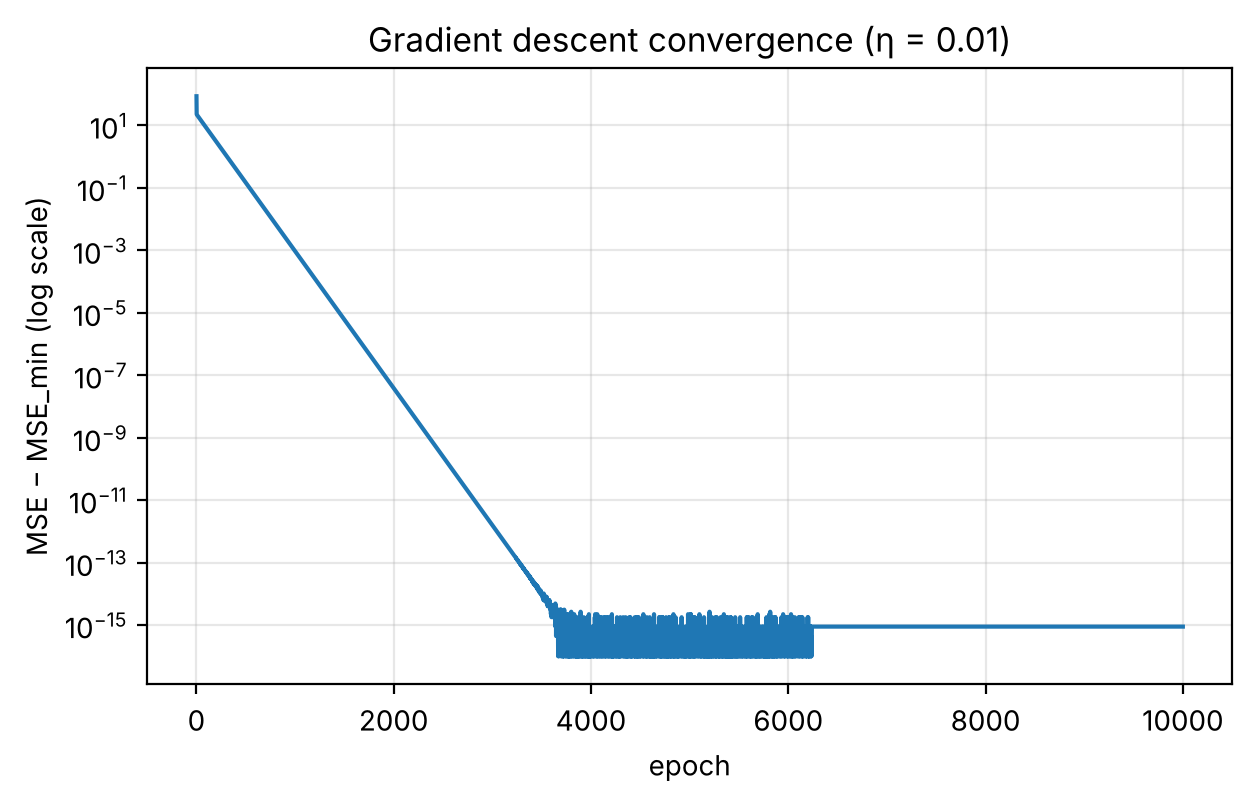

after   100 epochs: max |theta - theta_ols| = 5.72e+00
after  1000 epochs: max |theta - theta_ols| = 6.07e-02
after  3000 epochs: max |theta - theta_ols| = 2.48e-06
after 10000 epochs: max |theta - theta_ols| = 1.62e-13


In [6]:
mse_min = mean_squared_error(y, predict(x, theta_ols))  # the lowest achievable MSE (at the OLS solution)

fig, ax = plt.subplots(figsize=(7, 4))  # new figure with one set of axes
ax.semilogy(np.arange(1, N_EPOCHS + 1), np.maximum(losses - mse_min, 1e-16))  # log-scale excess loss per epoch
ax.set_xlabel("epoch")  # x-axis label
ax.set_ylabel("MSE − MSE_min (log scale)")  # y-axis label
ax.set_title(f"Gradient descent convergence (η = {LEARNING_RATE})")  # figure title
ax.grid(alpha=0.3, which="both")  # faint grid
plt.show()

for e in [100, 1000, 3000, 10000]:  # how close are we after a given number of epochs?
    t, _ = fit_gradient_descent(x, y, n_epochs=e)  # rerun GD for e epochs
    print(f"after {e:>5} epochs: max |theta - theta_ols| = {np.abs(t - theta_ols).max():.2e}")

<div dir="rtl">

**למה צריך כל כך הרבה epochs?**
- x לא ממורכז (x̄ = 5) והשונות שלו גדולה. לכן הקערה היא **עמק צר ומוארך**, עם condition number של ≈137.
- הכיוון התלול מכריח η קטן, והכיוון השטוח מתקדם לאט מאוד עם η כזה.

### ניסוי: מה קורה כש-η גדול מדי?

</div>

In [7]:
for lr in [0.01, 0.025, 0.05]:  # below the limit, close to the limit, above the limit
    try:
        with np.errstate(over="ignore", invalid="ignore"):  # silence numpy's overflow warning; our own check reports it
            t, _ = fit_gradient_descent(x, y, learning_rate=lr, n_epochs=3000)  # try this learning rate
        print(f"eta = {lr:<6} converged: theta = {np.round(t, 4)}")
    except RuntimeError as err:  # raised by our divergence check
        print(f"eta = {lr:<6} {err}")

H = (2 / N) * design_matrix(x).T @ design_matrix(x)  # Hessian of the MSE (constant for a quadratic loss)
eig = np.linalg.eigvalsh(H)  # eigenvalues = curvature of the bowl along its two principal axes
print(f"\nHessian eigenvalues: {np.round(eig, 3)}  ->  condition number = {eig[1] / eig[0]:.1f}")
print(f"stability limit: eta < 2 / lambda_max = {2 / eig[1]:.4f}")

eta = 0.01   converged: theta = [10.1289  2.884 ]
eta = 0.025  converged: theta = [10.1289  2.884 ]
eta = 0.05   Gradient descent diverged at epoch 391 (learning_rate=0.05 is too large)

Hessian eigenvalues: [ 0.504 68.843]  ->  condition number = 136.6
stability limit: eta < 2 / lambda_max = 0.0291


<div dir="rtl">

---
## סעיף c: MSE ו-R²

</div>

$$\text{MSE} = \frac{1}{N}\sum_i (y_i - \hat{y}_i)^2, \qquad R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}$$

<div dir="rtl">

- **MSE**: השגיאה הריבועית הממוצעת, ביחידות של (spikes/sec)².
- **R²**: איזה חלק מהשונות של y המודל מסביר, בהשוואה למודל הכי פשוט שיש, "תמיד לנחש את הממוצע ȳ".
  - R² = 1: התאמה מושלמת.
  - R² = 0: לא טוב יותר מהממוצע.
  - R² שלילי: **גרוע** מהממוצע. זה יכול לקרות על דאטה שהמודל לא ראה, כמו ב-cross-validation בשאלה 2.

</div>

In [8]:
def r_squared(y: np.ndarray, y_hat: np.ndarray) -> float:
    """R^2 = 1 - SS_res / SS_tot (fraction of variance explained)."""
    ss_res = np.sum((y - y_hat) ** 2)  # variance left unexplained by the model
    ss_tot = np.sum((y - np.mean(y)) ** 2)  # total variance around the mean (the "always guess y-bar" baseline)
    return float(1.0 - ss_res / ss_tot)  # 1 = perfect, 0 = no better than the mean, <0 = worse than the mean


y_hat = predict(x, theta_ols)  # model predictions at the observed x values
mse = mean_squared_error(y, y_hat)  # mean squared error of the fit
r2 = r_squared(y, y_hat)  # fraction of variance explained
print(f"MSE = {mse:.6f}   (RMSE = {np.sqrt(mse):.3f} spikes/sec)")
print(f"R^2 = {r2:.6f}")

MSE = 3.300567   (RMSE = 1.817 spikes/sec)
R^2 = 0.956251


<div dir="rtl">

**תשובה לסעיף c:** MSE ≈ **3.30**, ‏R² ≈ **0.956**.

**הפירוש:**
- עוצמת הגירוי מסבירה כ-**95.6%** מהשונות בקצב הירי. השאר הוא רעש.
- השורש של ה-MSE (≈1.8 spikes/sec) הוא הגודל הטיפוסי של הסטייה מהקו.

---
## סעיף d: Log-Likelihood

לפי המודל, כל תצפית מתפלגת נורמלית סביב הקו: yᵢ ~ N(ŷᵢ, σ²). התצפיות בלתי תלויות, ולכן ה-likelihood הוא **מכפלה** של 50 צפיפויות. לוקחים log, והמכפלה הופכת ל**סכום**:

</div>

$$\text{LL} = \sum_{i=1}^{N} \ln\!\left[\frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-\frac{(y_i-\hat{y}_i)^2}{2\sigma^2}}\right] = -\frac{N}{2}\ln(2\pi\sigma^2) \;-\; \frac{\text{SSE}}{2\sigma^2}$$

With $\sigma^2 = \text{MSE} = \text{SSE}/N$, the second term is $\frac{\text{SSE}}{2\,\text{SSE}/N} = \frac{N}{2}$, so:

$$\text{LL} = -\frac{N}{2}\Big[\ln(2\pi\cdot\text{MSE}) + 1\Big]$$

<div dir="rtl">

**הרגע החשוב:** האיבר היחיד ב-LL שתלוי ב-θ הוא **−SSE**. לכן מקסום ה-likelihood שקול למזעור SSE. **בהנחת רעש גאוסיאני, OLS = MLE.** בגלל זה השאלה נקראת "Linear Models and Maximum Likelihood".

</div>

In [9]:
def gaussian_log_likelihood(y: np.ndarray, y_hat: np.ndarray, sigma2: float) -> float:
    """LL = -N/2 * ln(2*pi*sigma^2) - SSE / (2*sigma^2)."""
    if sigma2 <= 0:  # a variance must be positive (log of 0 / division by 0 otherwise)
        raise ValueError("sigma2 must be positive")
    n = len(y)  # number of observations N
    sse = np.sum((y - y_hat) ** 2)  # sum of squared errors: the only term that depends on theta
    return float(-0.5 * n * np.log(2 * np.pi * sigma2) - sse / (2 * sigma2))  # normalisation + data-fit term


ll = gaussian_log_likelihood(y, y_hat, sigma2=mse)  # LL with the noise variance set to the MSE
ll_closed = -0.5 * N * (np.log(2 * np.pi * mse) + 1)  # same value via the simplified closed form

print("LL = -N/2 * ln(2*pi*MSE) - SSE/(2*MSE)")
print(f"   = -{N}/2 * ln(2*pi*{mse:.4f}) - {N}/2")
print(f"   = -{N / 2:.0f} * ({np.log(2 * np.pi * mse):.4f} + 1)")
print(f"   = {ll:.4f}")
print(f"closed-form check: {ll_closed:.4f}")

LL = -N/2 * ln(2*pi*MSE) - SSE/(2*MSE)
   = -50/2 * ln(2*pi*3.3006) - 50/2
   = -25 * (3.0320 + 1)
   = -100.7993
closed-form check: -100.7993


<div dir="rtl">

**תשובה לסעיף d:** LL ≈ **−100.80**.

LL שלילי זה תקין, כי log של צפיפויות קטנות הוא שלילי. המספר לבדו לא אומר הרבה. הוא שימושי **להשוואה בין מודלים** על אותו דאטה. וזה בדיוק הגשר לשאלה 3: AIC = N·ln(MSE) + 2k הוא, עד כדי קבוע, −2·LL ועוד קנס על מספר הפרמטרים.

---
## סעיף e: גרף של הדאטה וההתאמה

</div>

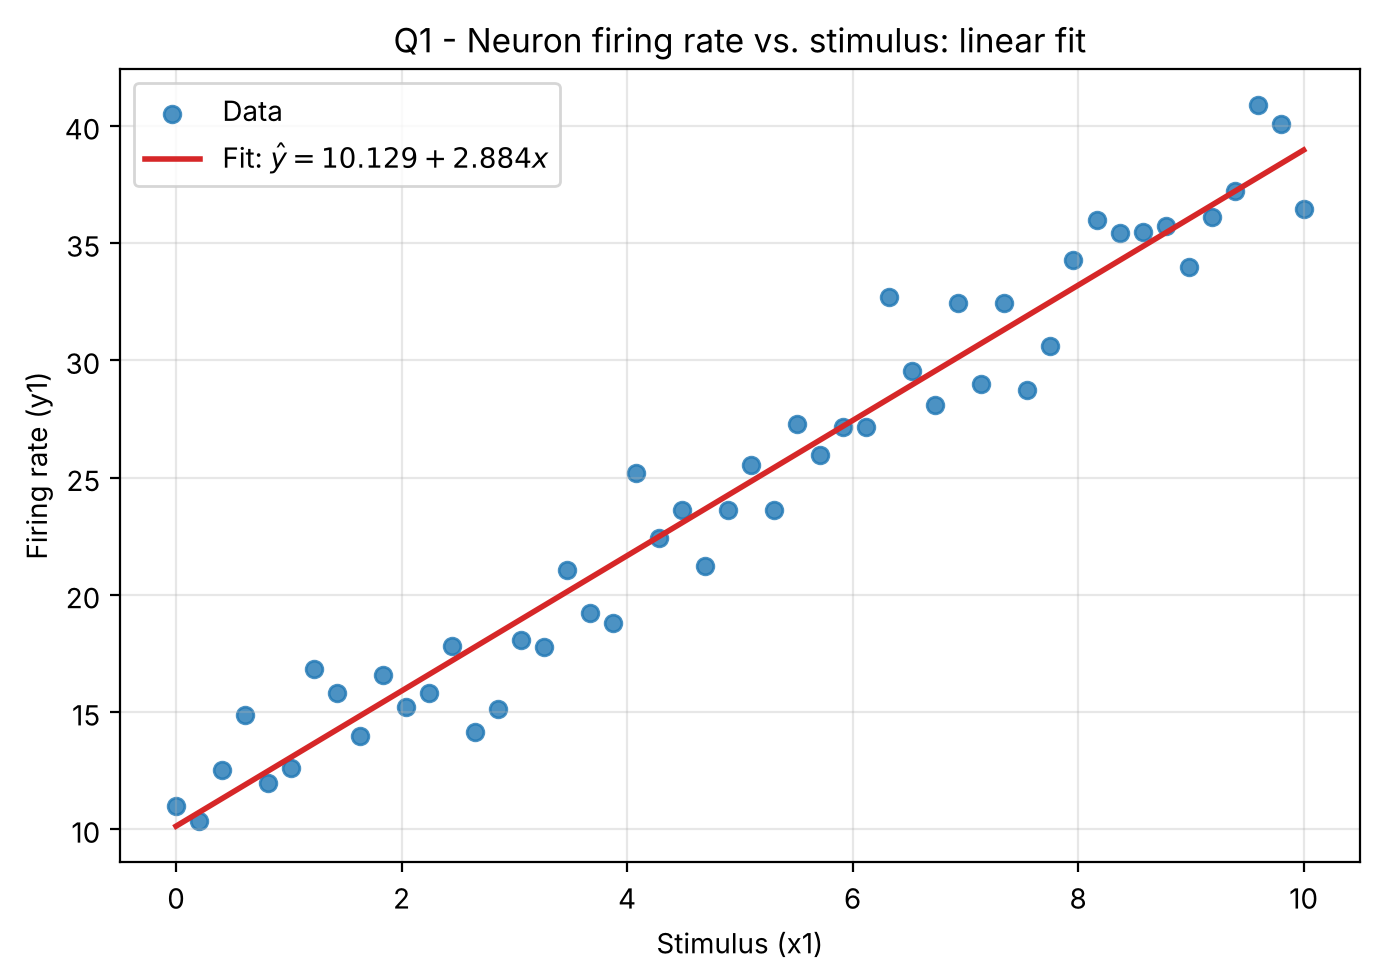

In [10]:
x_line = np.linspace(x.min(), x.max(), 200)  # 200 evenly spaced x values spanning the data range

fig, ax = plt.subplots(figsize=(7, 5))  # new figure (7x5 inches) with a single set of axes
ax.scatter(x, y, color="tab:blue", alpha=0.8, label="Data")  # the raw measurements as points
ax.plot(x_line, predict(x_line, theta_ols), color="tab:red", linewidth=2,  # the fitted line on top of the data
        label=rf"Fit: $\hat{{y}} = {theta_ols[0]:.3f} + {theta_ols[1]:.3f}x$")  # legend shows the fitted equation
ax.set_title("Q1 - Neuron firing rate vs. stimulus: linear fit")  # figure title
ax.set_xlabel("Stimulus (x1)")  # x-axis label
ax.set_ylabel("Firing rate (y1)")  # y-axis label
ax.legend()  # draw the legend from the `label=` arguments
ax.grid(alpha=0.3)  # faint grid
fig.tight_layout()  # adjust margins so labels are not clipped
fig.savefig("q1_linear_fit.png", dpi=150)  # save a copy for the report (Colab: Files panel on the left)
plt.show()

<div dir="rtl">

**מה לבדוק בגרף:** אלה ההנחות של המודל, וכאן כולן נראות סבירות:
- הנקודות מפוזרות **סימטרית** סביב הקו.
- **אין דפוס עקום** בשאריות.
- הפיזור **דומה** לאורך כל טווח x (homoscedasticity).

**הסתייגות ביולוגית:** נוירון אמיתי לא יורה בקצב שלילי, והוא מגיע לרוויה בגירוי חזק. לכן tuning curve אמיתית היא בדרך כלל סיגמואידית. המודל הלינארי תקף רק בטווח הדינמי שנמדד כאן.

---
## בונוס: למה GD איטי? הקערה לפני ואחרי נרמול

נרמול `z = (x − x̄) / σₓ` הופך את הקערה מעמק צר (condition number ≈ 137) ל**קערה עגולה** (condition number = 1). הפתרון לא משתנה, זה אותו קו בפרמטריזציה אחרת. משתנה רק הגאומטריה שבה GD מחפש.

</div>

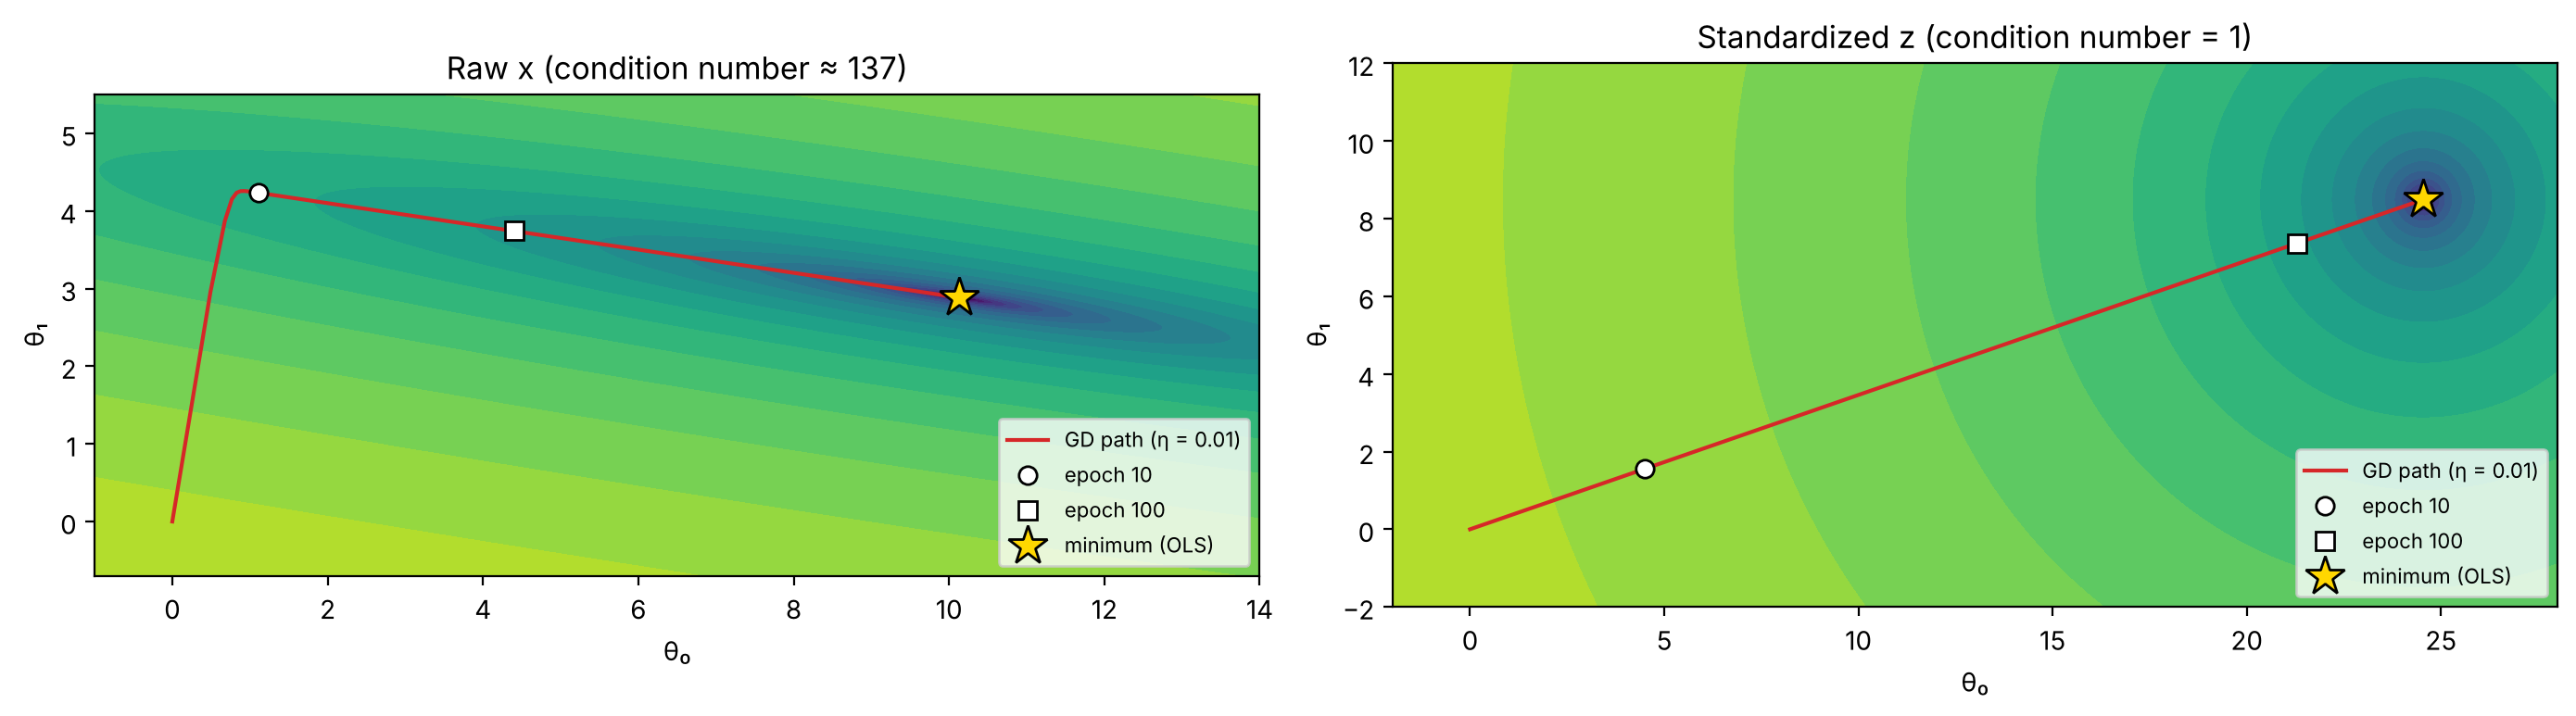

In [11]:
from matplotlib.colors import LogNorm  # logarithmic colour scale for the contour plot

z = (x - x.mean()) / x.std()  # standardised stimulus: mean 0, std 1
EPOCHS_DEMO = 3000  # epochs to draw


def gd_path(xv: np.ndarray, lr: float = 0.01) -> np.ndarray:
    """Run GD from (0, 0) and return every visited theta (for drawing the path)."""
    X = design_matrix(xv)  # design matrix for this version of x
    th = np.zeros(2)  # start at the origin
    path = [th.copy()]  # list of visited points
    for _ in range(EPOCHS_DEMO):  # same update rule as in section (b)
        th = th - lr * mse_gradient(X, y, th)
        path.append(th.copy())
    return np.array(path)  # shape (EPOCHS_DEMO + 1, 2)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # two panels side by side
panels = [(x, "Raw x (condition number ≈ 137)", (-1, 14), (-0.7, 5.5)),
          (z, "Standardized z (condition number = 1)", (-2, 28), (-2, 12))]
for ax, (xv, title, r0, r1) in zip(axes, panels):
    T0, T1 = np.meshgrid(np.linspace(*r0, 300), np.linspace(*r1, 300))  # grid over (theta0, theta1)
    M = np.mean((T0[..., None] + T1[..., None] * xv - y) ** 2, axis=-1)  # MSE at every grid point
    ax.contourf(T0, T1, M - M.min() + 1e-3, levels=np.logspace(-2, 3.5, 23), norm=LogNorm(), cmap="viridis")
    path = gd_path(xv)  # GD trajectory with eta = 0.01
    ax.plot(path[:, 0], path[:, 1], color="tab:red", lw=1.5, label="GD path (η = 0.01)")
    for e, mk in [(10, "o"), (100, "s")]:  # mark where GD is after 10 and 100 epochs
        ax.plot(*path[e], mk, color="white", mec="black", ms=7, label=f"epoch {e}")
    ax.plot(*fit_analytical(xv, y), "*", color="gold", mec="black", ms=16, label="minimum (OLS)")
    ax.set_aspect("equal")  # same scale on both axes so the bowl's true shape is visible
    ax.set_xlim(r0); ax.set_ylim(r1)
    ax.set_title(title); ax.set_xlabel("θ₀"); ax.set_ylabel("θ₁")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

<div dir="rtl">

**איך לקרוא את הגרף:**
- **שמאל (x מקורי):** GD קופץ מהר לרצפת העמק (עד epoch 10), ואז **זוחל** לאורכו. אחרי 100 epochs θ₀ עדיין רחוק מ-10.
- **ימין (x מנורמל):** קווי הגובה הם מעגלים. הגרדיאנט מצביע ישר למרכז, ולכן המסלול הוא **קו ישר** למינימום.

---
## סיכום התשובות לשאלה 1

</div>

In [12]:
summary = pd.DataFrame(  # one table with every number the question asks for
    {
        "value": [theta_ols[0], theta_ols[1], theta_gd[0], theta_gd[1], mse, r2, ll],
    },
    index=["(a) θ0 analytical", "(a) θ1 analytical", "(b) θ0 GD", "(b) θ1 GD", "(c) MSE", "(c) R²", "(d) LL"],
)
summary.style.format("{:.4f}")  # display with 4 decimal places

,value
(a) θ0 analytical,10.1289
(a) θ1 analytical,2.8840
(b) θ0 GD,10.1289
(b) θ1 GD,2.8840
(c) MSE,3.3006
(c) R²,0.9563
(d) LL,-100.7993


<div dir="rtl">

| סעיף | תשובה |
|---|---|
| **a** | θ₀ ≈ 10.129, θ₁ ≈ 2.884 (משוואות נורמליות) |
| **b** | η = 0.01, ‏10,000 epochs, התחלה מ-(0,0). זהה לאנליטי עד ~10⁻¹³ |
| **c** | MSE ≈ 3.30, ‏R² ≈ 0.956 |
| **d** | LL = −(N/2)·[ln(2π·MSE) + 1] ≈ −100.80 |
| **e** | הגרף למעלה (נשמר גם בשם `q1_linear_fit.png`) |

</div>